# S10 - Series de tiempo e inferencia en streaming

Continúa el Data Lake Gold de S04 (`campo_electrico_particionado`): hoy la pregunta cambia de "¿qué otras variables explican `CE` en el mismo instante?" (S04) a "¿el historial de `CE` predice su propio futuro?" (S10).

## Fase 1 — Business Understanding

**Objetivo:** estimar `CE` en el minuto siguiente (`label = CE_t+1`) a partir de las 8 variables físicas medidas en el minuto actual (`CE_t, CM_t, TempOut_t, OutHum_t, WindSpeed_t, Bar_t, SolarRad_t, UVIndex_t`), reutilizando el Data Lake Gold de S04 — sin reentrenar la integración ni la limpieza, ya resueltas ahí.

**Alcance:** comparar un modelo de regresión lineal y un Random Forest, ambos entrenados sobre el mismo dataset con división cronológica, contra un baseline de persistencia (`CE_t+1 ≈ CE_t`). El ganador se guarda como `PipelineModel` y se aplica después sobre lecturas que llegan en tiempo real por Kafka.

In [1]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .appName("sesion10-series-tiempo-inferencia")
    .master("local[*]")
    .config("spark.jars.packages", "org.apache.spark:spark-sql-kafka-0-10_2.13:4.2.0")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")
spark

:: loading settings :: url = jar:file:/usr/local/lib/python3.10/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /root/.ivy2.5.2/cache
The jars for the packages stored in: /root/.ivy2.5.2/jars
org.apache.spark#spark-sql-kafka-0-10_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-63a81329-df9b-4273-8fe7-780239aa91ca;1.0
	confs: [default]


	found org.apache.spark#spark-sql-kafka-0-10_2.13;4.2.0 in central
	found org.apache.spark#spark-token-provider-kafka-0-10_2.13;4.2.0 in central
	found org.apache.kafka#kafka-clients;3.9.2 in central
	found at.yawk.lz4#lz4-java;1.11.0 in central
	found org.xerial.snappy#snappy-java;1.1.10.8 in central
	found org.slf4j#slf4j-api;2.0.17 in central
	found org.apache.hadoop#hadoop-client-runtime;3.5.0 in central
	found org.apache.hadoop#hadoop-client-api;3.5.0 in central
	found com.google.code.findbugs#jsr305;3.0.0 in central


	found org.scala-lang.modules#scala-parallel-collections_2.13;1.2.0 in central
	found org.apache.commons#commons-pool2;2.13.1 in central
:: resolution report :: resolve 352ms :: artifacts dl 14ms
	:: modules in use:
	at.yawk.lz4#lz4-java;1.11.0 from central in [default]
	com.google.code.findbugs#jsr305;3.0.0 from central in [default]
	org.apache.commons#commons-pool2;2.13.1 from central in [default]
	org.apache.hadoop#hadoop-client-api;3.5.0 from central in [default]
	org.apache.hadoop#hadoop-client-runtime;3.5.0 from central in [default]
	org.apache.kafka#kafka-clients;3.9.2 from central in [default]
	org.apache.spark#spark-sql-kafka-0-10_2.13;4.2.0 from central in [default]
	org.apache.spark#spark-token-provider-kafka-0-10_2.13;4.2.0 from central in [default]
	org.scala-lang.modules#scala-parallel-collections_2.13;1.2.0 from central in [default]
	org.slf4j#slf4j-api;2.0.17 from central in [default]
	org.xerial.snappy#snappy-java;1.1.10.8 from central in [default]
	-------------------

26/10/17 19:58:53 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


## Fase 2 — Data Understanding

### 2.1 Cargar el Data Lake Gold de S04

`campo_electrico_particionado/` ya viene integrado, sin el código de error `CM=99999`, sin nulos y sin `DateTime` duplicada (S04, 3.3.2) — nada de eso se repite hoy.

In [2]:
RUTA_GOLD_S04 = "../s04-ml-distribuido-regresion/artifacts/campo_electrico_particionado"
VARIABLES_8 = ["CE", "CM", "TempOut", "OutHum", "WindSpeed", "Bar", "SolarRad", "UVIndex"]

df_gold = spark.read.parquet(RUTA_GOLD_S04)
print(f"Filas del Gold de S04: {df_gold.count():,}")
df_gold.orderBy("DateTime").show(5)

Filas del Gold de S04: 92,847


+-------------------+-----+-------+-------+------+---------+-----+--------+-------+-------+
|           DateTime|   CE|     CM|TempOut|OutHum|WindSpeed|  Bar|SolarRad|UVIndex|AnioMes|
+-------------------+-----+-------+-------+------+---------+-----+--------+-------+-------+
|2026-05-10 00:00:00|-0.28|24194.3|   16.7|  86.0|      0.0|947.3|     0.0|    0.0|2026-05|
|2026-05-10 00:01:00|-0.34|24193.8|   16.7|  86.0|      0.0|947.3|     0.0|    0.0|2026-05|
|2026-05-10 00:02:00|-0.39|24193.6|   16.7|  86.0|      0.0|947.3|     0.0|    0.0|2026-05|
|2026-05-10 00:03:00|-0.43|24194.4|   16.7|  86.0|      0.0|947.3|     0.0|    0.0|2026-05|
|2026-05-10 00:04:00|-0.38|24195.2|   16.7|  86.0|      0.0|947.3|     0.0|    0.0|2026-05|
+-------------------+-----+-------+-------+------+---------+-----+--------+-------+-------+
only showing top 5 rows


## Fase 3 — Data Preparation

### 3.1 Construir el objetivo futuro (`label`)

`lead("CE", 1)` sobre el orden cronológico trae, en la fila del minuto `t`, el valor de `CE` observado en `t+1`. La última fila de la tabla no tiene un "minuto siguiente" — `na.drop()` la descarta junto con cualquier fila con un predictor nulo.

In [3]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window

orden_temporal = Window.orderBy("DateTime")

dataset_ml = (
    df_gold
    .withColumn("label", F.lead("CE", 1).over(orden_temporal))
    .select("DateTime", *VARIABLES_8, "label")
    .na.drop()
)

print(f"Filas del Gold: {df_gold.count():,}")
print(f"Filas del dataset supervisado (una menos, por el ultimo lead sin futuro): {dataset_ml.count():,}")
dataset_ml.show(5)

Filas del Gold: 92,847


26/10/17 19:59:02 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:02 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/10/17 19:59:02 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:02 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


Filas del dataset supervisado (una menos, por el ultimo lead sin futuro): 92,846


26/10/17 19:59:02 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:02 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:02 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


+-------------------+-----+-------+-------+------+---------+-----+--------+-------+-----+
|           DateTime|   CE|     CM|TempOut|OutHum|WindSpeed|  Bar|SolarRad|UVIndex|label|
+-------------------+-----+-------+-------+------+---------+-----+--------+-------+-----+
|2026-05-10 00:00:00|-0.28|24194.3|   16.7|  86.0|      0.0|947.3|     0.0|    0.0|-0.34|
|2026-05-10 00:01:00|-0.34|24193.8|   16.7|  86.0|      0.0|947.3|     0.0|    0.0|-0.39|
|2026-05-10 00:02:00|-0.39|24193.6|   16.7|  86.0|      0.0|947.3|     0.0|    0.0|-0.43|
|2026-05-10 00:03:00|-0.43|24194.4|   16.7|  86.0|      0.0|947.3|     0.0|    0.0|-0.38|
|2026-05-10 00:04:00|-0.38|24195.2|   16.7|  86.0|      0.0|947.3|     0.0|    0.0|-0.35|
+-------------------+-----+-------+-------+------+---------+-----+--------+-------+-----+
only showing top 5 rows


26/10/17 19:59:02 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:02 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


### 3.2 División cronológica 80/20

Igual que S04 anticipó (Tabla 7): el orden de las filas es el dato. `randomSplit` filtraría al azar, mezclando minutos futuros dentro del entrenamiento — por eso se numeran las filas por su orden temporal y se corta por posición, no al azar.

In [4]:
numerado = dataset_ml.withColumn("numeroFila", F.row_number().over(orden_temporal))
total_filas = numerado.count()
corte = int(total_filas * 0.80)

train = numerado.filter(F.col("numeroFila") <= corte).drop("numeroFila")
test = numerado.filter(F.col("numeroFila") > corte).drop("numeroFila")

fecha_max_train = train.agg(F.max("DateTime")).first()[0]
fecha_min_test = test.agg(F.min("DateTime")).first()[0]
if fecha_max_train >= fecha_min_test:
    raise ValueError("La division temporal no respeta el orden cronologico.")

print(f"Entrenamiento: {train.count():,} filas (hasta {fecha_max_train})")
print(f"Prueba: {test.count():,} filas (desde {fecha_min_test})")

26/10/17 19:59:03 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:03 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/10/17 19:59:03 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:03 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/10/17 19:59:03 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:03 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:03 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:03 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/10/17 19:59:03 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:03 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:03 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:03 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/10/17 19:59:03 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:03 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:03 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:03 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:04 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:04 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 1

26/10/17 19:59:04 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:04 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:04 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:04 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:04 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:04 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 1

Entrenamiento: 74,276 filas (hasta 2026-08-19 23:15:00)


26/10/17 19:59:04 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:04 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:04 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:04 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:04 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:04 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 1

Prueba: 18,570 filas (desde 2026-08-19 23:16:00)


#### 3.3 Baseline de persistencia

Antes de entrenar nada: ¿qué tan bueno es simplemente asumir que `CE` no cambia de un minuto a otro (`CE_t+1 ≈ CE_t`)? Ningún modelo entrenado tiene sentido reportarlo si no supera esto — el mismo principio de 1.6 de S04 (comparar contra una alternativa antes de confiar en un modelo).

In [5]:
from pyspark.ml.evaluation import RegressionEvaluator

evaluador_rmse = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="rmse")
evaluador_mae = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="mae")
evaluador_r2 = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="r2")

def evaluar(predicciones, nombre):
    resultado = {
        "Modelo": nombre,
        "RMSE": evaluador_rmse.evaluate(predicciones),
        "MAE": evaluador_mae.evaluate(predicciones),
        "R2": evaluador_r2.evaluate(predicciones),
    }
    print(f"{nombre}: RMSE={resultado['RMSE']:.4f}  MAE={resultado['MAE']:.4f}  R2={resultado['R2']:.4f}")
    return resultado

test_persistencia = test.withColumn("prediction", F.col("CE"))
resultado_persistencia = evaluar(test_persistencia, "Persistencia (CE_t+1 = CE_t)")

26/10/17 19:59:04 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:04 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:04 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:04 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:04 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:05 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 1

26/10/17 19:59:05 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:05 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:05 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:05 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:05 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:05 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 1

26/10/17 19:59:05 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:05 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:05 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:05 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:05 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:05 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 1

Persistencia (CE_t+1 = CE_t): RMSE=0.2087  MAE=0.1316  R2=0.9461


## Fase 4 — Modeling

### 4.1 Regresión lineal

Mismo patrón de S04: `VectorAssembler` ensambla las 8 variables en `features`; `LinearRegression` ya estandariza internamente (`standardization=True` por defecto), así que no hace falta un `StandardScaler` aparte (S04, 2.6/3.3.6).

In [6]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression

ensamblador = VectorAssembler(inputCols=VARIABLES_8, outputCol="features")
train_ml = ensamblador.transform(train)
test_ml = ensamblador.transform(test)

lr = LinearRegression(featuresCol="features", labelCol="label")
modelo_lr = lr.fit(train_ml)

print("Coeficientes (orden de VARIABLES_8):", modelo_lr.coefficients)
print("Intercepto:", modelo_lr.intercept)

predicciones_lr = modelo_lr.transform(test_ml)
resultado_lr = evaluar(predicciones_lr, "LinearRegression")

26/10/17 19:59:05 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:05 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:05 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:05 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:05 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:06 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 1

26/10/17 19:59:06 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:06 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:06 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:06 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:06 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:06 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 1

26/10/17 19:59:06 WARN Instrumentation: [e557e04b] regParam is zero, which might cause numerical instability and overfitting.
netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory


netlib-lapack: JNI_OnLoad: dlopen(liblapack.so.3) failed: liblapack.so.3: cannot open shared object file: No such file or directory
26/10/17 19:59:06 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:06 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:06 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:06 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:06 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/10/17 19:59:07 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:07 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:07 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:07 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


Coeficientes (orden de VARIABLES_8): [0.9791366875356321,-6.924258006309083e-05,0.002585980603258878,9.539825580407314e-05,-0.0015418258936142747,0.0005752406679506272,3.869127783512777e-06,0.0002500633939482393]
Intercepto: 1.0637345956083166


26/10/17 19:59:07 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:07 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:07 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:07 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:07 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:07 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 1

26/10/17 19:59:07 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:07 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:07 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:07 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:07 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:07 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 1

26/10/17 19:59:07 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:07 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:07 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:07 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:07 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:08 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 1

LinearRegression: RMSE=0.2073  MAE=0.1325  R2=0.9468


### 4.2 Random Forest

Mismo algoritmo que S04 (`RandomForestRegressor`), sin supuesto de linealidad — útil para confirmar si la relación real es, de fondo, aproximadamente lineal.

In [7]:
from pyspark.ml.regression import RandomForestRegressor

rf = RandomForestRegressor(featuresCol="features", labelCol="label", numTrees=50, maxDepth=8, seed=42)
modelo_rf = rf.fit(train_ml)

predicciones_rf = modelo_rf.transform(test_ml)
resultado_rf = evaluar(predicciones_rf, "RandomForestRegressor")

importancias = sorted(zip(VARIABLES_8, modelo_rf.featureImportances.toArray()), key=lambda par: -par[1])
for variable, importancia in importancias:
    print(f"{variable:10s} {importancia:.4f}")

26/10/17 19:59:08 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:08 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:08 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:08 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:08 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:08 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 1

26/10/17 19:59:11 WARN DAGScheduler: Broadcasting large task binary with size 1040.7 KiB


26/10/17 19:59:12 WARN DAGScheduler: Broadcasting large task binary with size 1984.5 KiB


26/10/17 19:59:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 1

26/10/17 19:59:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 1

26/10/17 19:59:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 1

RandomForestRegressor: RMSE=0.2528  MAE=0.1692  R2=0.9209
CE         0.8704
CM         0.0327
TempOut    0.0317
OutHum     0.0271
WindSpeed  0.0161
UVIndex    0.0082
Bar        0.0072
SolarRad   0.0064


## Fase 5 — Evaluation

### 5.1 Comparar contra el baseline

Si un modelo no le gana a la persistencia, su complejidad adicional no se justifica (S04, Tabla 2, columna "Series de tiempo").

In [8]:
import pandas as pd

comparacion = pd.DataFrame([resultado_persistencia, resultado_lr, resultado_rf])
comparacion["MejoraRMSE_vs_persistencia_%"] = (
    100 * (resultado_persistencia["RMSE"] - comparacion["RMSE"]) / resultado_persistencia["RMSE"]
)
comparacion

,Modelo,RMSE,MAE,R2,MejoraRMSE_vs_persistencia_%
0,Persistencia (CE_t+1 = CE_t),0.208695,0.131590,0.946103,0.000000
1,LinearRegression,0.207271,0.132527,0.946836,0.682421
2,RandomForestRegressor,0.252838,0.169171,0.920891,-21.151670


## Fase 6 — Deployment

### 6.1 Guardar el modelo seleccionado

Se guarda el `Pipeline` completo (`VectorAssembler` + modelo ganador), no solo el estimador — así la inferencia de la siguiente sección no tiene que repetir el ensamblado a mano.

In [9]:
from pyspark.ml import Pipeline, PipelineModel

RUTA_MODELO = "./artifacts/models/modelo_ce_lr"

pipeline_ganador = Pipeline(stages=[VectorAssembler(inputCols=VARIABLES_8, outputCol="features"), LinearRegression(featuresCol="features", labelCol="label")])
modelo_final = pipeline_ganador.fit(train)
modelo_final.write().overwrite().save(RUTA_MODELO)

modelo_cargado = PipelineModel.load(RUTA_MODELO)
print("Modelo guardado y recargado en:", RUTA_MODELO)
modelo_cargado.transform(test).select(*VARIABLES_8, "label", "prediction").show(5)

26/10/17 19:59:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 1

26/10/17 19:59:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:14 WARN Instrumentation: [4feb0de5] regParam is zero, which might cause numerical instability and overfitting.


26/10/17 19:59:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:14 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 1

Modelo guardado y recargado en: ./artifacts/models/modelo_ce_lr


26/10/17 19:59:19 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:19 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:19 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:19 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:19 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 19:59:19 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 1

+----+-------+-------+------+---------+-----+--------+-------+-----+-------------------+
|  CE|     CM|TempOut|OutHum|WindSpeed|  Bar|SolarRad|UVIndex|label|         prediction|
+----+-------+-------+------+---------+-----+--------+-------+-----+-------------------+
|0.13|24262.7|   13.3|  91.0|      0.0|951.0|     0.0|    0.0| 0.14|0.10113907621375495|
|0.14|24261.3|   13.3|  91.0|      0.0|951.0|     0.0|    0.0| 0.15|0.11102738270119983|
|0.15|24261.9|   13.3|  91.0|      0.0|951.0|     0.0|    0.0| 0.13|0.12077720402851799|
|0.13|24261.0|   13.3|  91.0|      0.0|951.0|     0.0|    0.0| 0.11|0.10125678859986231|
|0.11|24260.7|   13.3|  91.0|      0.0|950.8|     0.0|    0.0|  0.1|0.08157977948957829|
+----+-------+-------+------+---------+-----+--------+-------+-----+-------------------+
only showing top 5 rows


## Inferencia en tiempo real

El modelo guardado solo necesita la **última medición** para predecir — no mantiene historial ni estado entre lecturas (confirmado en 4.1/4.2: las 8 variables ya son del mismo instante `t`). Eso simplifica mucho la inferencia en streaming: cada evento nuevo que llega por Kafka se transforma directo con `modelo_cargado.transform()`, sin ventanas ni agregaciones con estado.

Antes de correr la siguiente celda, levantar el productor sintético en otra terminal:

```bash
cd uso-campo-electrico
docker compose up -d
docker exec -it lambda26-uso-campo-electrico python producer_campo_electrico.py
```

In [10]:
from pyspark.sql.types import StructType, StringType, DoubleType, LongType

esquema_evento = (
    StructType()
    .add("tipoEvento", StringType())
    .add("estacionId", StringType())
    .add("CE", DoubleType())
    .add("CM", DoubleType())
    .add("TempOut", DoubleType())
    .add("OutHum", DoubleType())
    .add("WindSpeed", DoubleType())
    .add("Bar", DoubleType())
    .add("SolarRad", DoubleType())
    .add("UVIndex", DoubleType())
    .add("origen", StringType())
    .add("timestamp", LongType())
)

crudo = (
    spark.readStream.format("kafka")
    .option("kafka.bootstrap.servers", "kafka:9092")
    .option("subscribe", "campo-electrico-eventos")
    .option("startingOffsets", "latest")
    .option("failOnDataLoss", "false")
    .load()

)

eventos = (
    crudo.select(F.col("value").cast("string").alias("json_str"))
    .select(F.from_json(F.col("json_str"), esquema_evento).alias("e"))
    .select("e.*")
)

predicciones_stream = modelo_cargado.transform(eventos)

In [11]:
if "consulta_predicciones" in dir() and consulta_predicciones.isActive:
    print("Deteniendo la consulta anterior antes de arrancar una nueva...")
    consulta_predicciones.stop()


In [12]:
RUTA_PREDICCIONES_STREAM = "./artifacts/predicciones_stream"
CHECKPOINT_STREAM = "./artifacts/chk_predicciones_stream"

In [13]:
#correr en caso de error en el anterior bloque
#import shutil
#shutil.rmtree("./artifacts/chk_predicciones_stream", ignore_errors=True)
#shutil.rmtree("./artifacts/predicciones_stream", ignore_errors=True)
import os
import shutil
from pyspark.sql.utils import AnalysisException

COLUMNAS_ESPERADAS = {"batchId", "estacionId", "fechaHora", "CE", "prediccionSiguienteCE"}

limpiar = False
if os.path.exists(RUTA_PREDICCIONES_STREAM):
    try:
        columnas_actuales = set(spark.read.parquet(RUTA_PREDICCIONES_STREAM).columns)
        limpiar = columnas_actuales != COLUMNAS_ESPERADAS
        if limpiar:
            print(f"Esquema desactualizado ({columnas_actuales}) — limpiando checkpoint y predicciones.")
    except AnalysisException:
        limpiar = True  # carpeta corrupta o vacía, mejor empezar de cero

if limpiar:
    shutil.rmtree(CHECKPOINT_STREAM, ignore_errors=True)
    shutil.rmtree(RUTA_PREDICCIONES_STREAM, ignore_errors=True)
else:
    print("Esquema al día — no hace falta limpiar nada.")


Esquema al día — no hace falta limpiar nada.


In [14]:
def guardar_predicciones_microlote(df_microlote, id_lote):
    filas = df_microlote.count()
    if filas == 0:
        print(f"Micro-lote {id_lote}: sin filas")
        return
    df_microlote.select(
        F.lit(id_lote).alias("batchId"), "estacionId",
        (F.col("timestamp") / 1000).cast("timestamp").alias("fechaHora"), "CE",
        F.col("prediction").alias("prediccionSiguienteCE"),
    ).write.mode("append").parquet(RUTA_PREDICCIONES_STREAM)
    print(f"Micro-lote {id_lote}: {filas} predicciones guardadas")

# Momento 1: arrancar la consulta
consulta_predicciones = (
    predicciones_stream.writeStream
    .foreachBatch(guardar_predicciones_microlote)
    .option("checkpointLocation", CHECKPOINT_STREAM)
    .start()
)

26/10/17 19:59:19 WARN ResolveWriteToStream: spark.sql.adaptive.enabled is not supported in streaming DataFrames/Datasets and will be disabled.


In [15]:
import time
time.sleep(90)  # deja correr la inferencia en vivo sobre campo-electrico-eventos
print("micro-lotes procesados:", len(consulta_predicciones.recentProgress))

Micro-lote 0: sin filas


Micro-lote 1: 1 predicciones guardadas


Micro-lote 2: 1 predicciones guardadas


Micro-lote 3: 1 predicciones guardadas


Micro-lote 4: 1 predicciones guardadas


...

Micro-lote 26: 1 predicciones guardadas


Micro-lote 27: 1 predicciones guardadas


Micro-lote 28: 1 predicciones guardadas


Micro-lote 29: 1 predicciones guardadas


Micro-lote 30: 1 predicciones guardadas
micro-lotes procesados: 31


Con la consulta arrancada, **no la detengas todavía** — déjala corriendo en segundo plano mientras sigues con el resto de la sesión (3.8, evidencia). Vuelve a esta sección recién al final, justo antes de cerrar el notebook.

## Cierre de la sesión: detener la consulta y revisar resultados

Esto es lo último que corres hoy, después de haber trabajado el resto de la guía (3.8) con la consulta corriendo en segundo plano todo ese tiempo.

In [16]:
# Momento 2: detener la consulta (al final de la sesión, no antes)
consulta_predicciones.stop()

26/10/17 20:00:50 WARN DAGScheduler: Failed to cancel job group f58f069c-3ecb-4c84-984f-8dc82a469413. Cannot find active jobs for it.
26/10/17 20:00:50 WARN DAGScheduler: Failed to cancel job group f58f069c-3ecb-4c84-984f-8dc82a469413. Cannot find active jobs for it.


In [17]:
spark.read.parquet(RUTA_PREDICCIONES_STREAM).orderBy(F.desc("batchId")).show(20, truncate=False)

+-------+--------------+-----------------------+----+---------------------+
|batchId|estacionId    |fechaHora              |CE  |prediccionSiguienteCE|
+-------+--------------+-----------------------+----+---------------------+
|30     |estacion-ns-01|2026-10-17 20:00:48.295|0.9 |0.8584775992567315   |
|29     |estacion-ns-01|2026-10-17 20:00:45.293|0.95|0.9071706412703222   |
|28     |estacion-ns-01|2026-10-17 20:00:42.291|1.02|0.9762665859734394   |
|27     |estacion-ns-01|2026-10-17 20:00:39.289|1.04|0.9958892274657941   |
|26     |estacion-ns-01|2026-10-17 20:00:36.287|1.04|0.9960877612926086   |
|25     |estacion-ns-01|2026-10-17 20:00:33.286|1.11|1.0651222984965227   |
|24     |estacion-ns-01|2026-10-17 20:00:30.286|1.15|1.1042329663972343   |
|23     |estacion-ns-01|2026-10-17 20:00:27.284|1.09|1.045729231100819    |
|22     |estacion-ns-01|2026-10-17 20:00:24.282|1.05|1.005862453302163    |
|21     |estacion-ns-01|2026-10-17 20:00:21.28 |1.01|0.967044791285661    |
|20     |est

### Entrenamiento, prueba y streaming, en un solo gráfico

`train`/`test` son datos **históricos** (el Gold de S04); el streaming de arriba es de **hoy**. Usar fechas reales en el eje X dejaría un hueco de semanas entre donde termina `test` y donde empieza el streaming — en vez de eso, el eje X es **secuencia** (posición), no tiempo real: cada etapa va una después de la otra, separadas por una línea vertical, sin fingir que son continuas en el calendario.

In [18]:
!pip install matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.1/8.8 MB 1.7 MB/s eta 0:00:06

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.1/8.8 MB 1.6 MB/s eta 0:00:06

     ━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.3/8.8 MB 2.2 MB/s eta 0:00:04

     ━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.5/8.8 MB 2.9 MB/s eta 0:00:03

     ━━━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.9/8.8 MB 4.0 MB/s eta 0:00:02

...

     ━━━━━━━━━━━━━━━━━━━━━━━━━━╸━━━━━━━━━━ 235.5/325.0 kB 648.6 kB/s eta 0:00:01

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╺━━━━━━━ 256.0/325.0 kB 668.1 kB/s eta 0:00:01

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╺━━━━━ 276.5/325.0 kB 651.6 kB/s eta 0:00:01

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 325.0/325.0 kB 638.2 kB/s eta 0:00:00



[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
26/10/17 20:01:19 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 20:01:19 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 20:01:19 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 20:01:19 WARN WindowExec: No Partition Defined for Window op

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)
26/10/17 20:01:20 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 20:01:20 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 20:01:20 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 20:01:20 WARN WindowExec: No Partition Defined for Window op

26/10/17 20:01:20 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 20:01:20 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 20:01:20 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/17 20:01:20 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


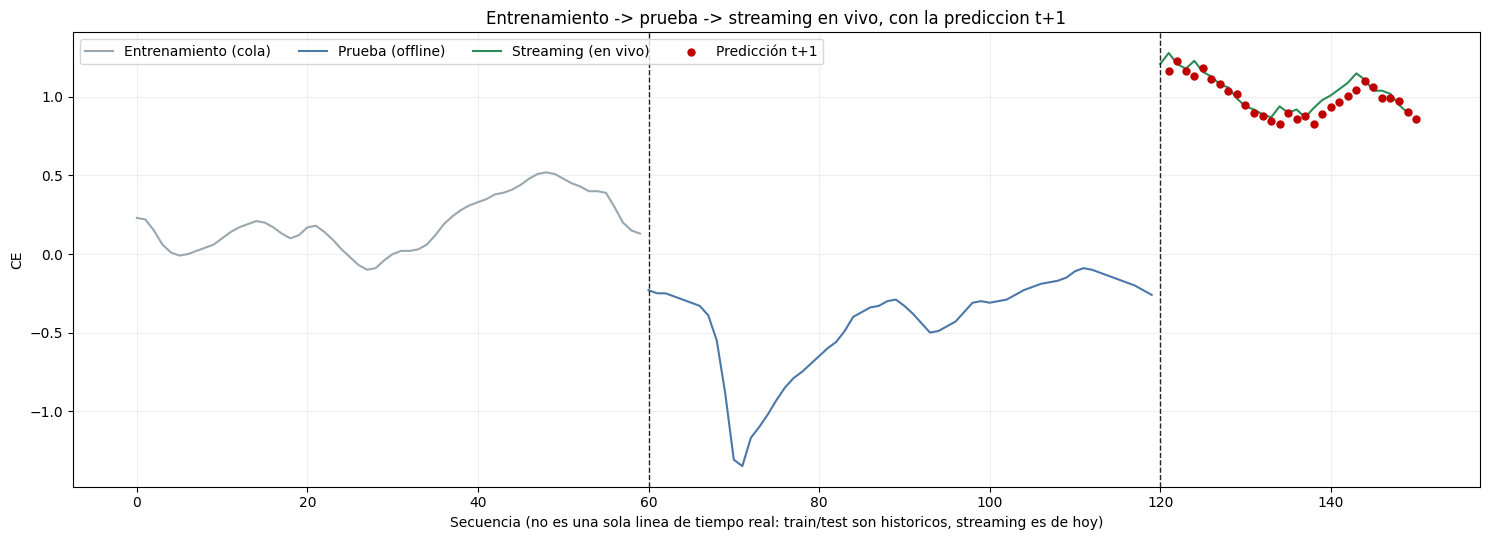

In [19]:
import matplotlib.pyplot as plt
import pandas as pd

N_COLA = 60
cola_train = (
    train.orderBy(F.desc("DateTime")).limit(N_COLA)
    .orderBy("DateTime").select("CE").toPandas()
)
cola_test = (
    test.orderBy(F.desc("DateTime")).limit(N_COLA)
    .orderBy("DateTime").select("CE").toPandas()
)
stream_pd = spark.read.parquet(RUTA_PREDICCIONES_STREAM).orderBy("fechaHora").toPandas()

n_train, n_test, n_stream = len(cola_train), len(cola_test), len(stream_pd)

fig, ax = plt.subplots(figsize=(15, 5.5))
ax.plot(range(n_train), cola_train["CE"], label="Entrenamiento (cola)", color="#9AA7B0")
ax.plot(range(n_train, n_train + n_test), cola_test["CE"], label="Prueba (offline)", color="#4C78A8")
x_stream = list(range(n_train + n_test, n_train + n_test + n_stream))
ax.plot(x_stream, stream_pd["CE"], label="Streaming (en vivo)", color="#2E8B57")
ax.scatter(
    [x + 1 for x in x_stream], stream_pd["prediccionSiguienteCE"],
    color="#C00000", label="Predicción t+1", zorder=5, s=25,
)

ax.axvline(n_train, color="#222222", linestyle="--", linewidth=1)
ax.axvline(n_train + n_test, color="#222222", linestyle="--", linewidth=1)

ax.set_title("Entrenamiento -> prueba -> streaming en vivo, con la prediccion t+1")
ax.set_xlabel("Secuencia (no es una sola linea de tiempo real: train/test son historicos, streaming es de hoy)")
ax.set_ylabel("CE")
ax.legend(ncol=4)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

La línea gris (entrenamiento) y la azul (prueba) muestran el mismo comportamiento que ya viste al evaluar los modelos (5.1) — ahora en contexto, justo antes del punto donde arrancó la inferencia real. La línea verde es exactamente lo que capturó `guardar_predicciones_microlote` en esta corrida; los puntos rojos son la predicción de cada micro-lote para el minuto siguiente, desplazados un paso a la derecha de su `CE` observado — así quedan alineados con el instante que en realidad predicen.

**No te alarmes si hay un salto grande de nivel entre `test` y el streaming** — no es un modelo malo. `producer_campo_electrico.py` arranca `CE` en un punto **aleatorio dentro de todo el rango histórico calibrado** (`-6.74` a `2.85`) cada vez que el contenedor inicia — no continúa desde el último valor real de `test`. El punto de comparación correcto no es "¿el streaming sigue donde terminó `test`?" (no tiene por qué), sino "¿la línea roja (predicción) sigue de cerca a la verde (`CE` real), sin importar en qué nivel estén ambas?" — esa es la pregunta que sí mide si el modelo funciona.